In [21]:
# !pip install tensorflow keras scikit-learn matplotlib kagglehub numpy

# Запуск з використанням CUDA-ядер

1. Навідміну від PyTorch, у tensorflow використовувати CUDA-ядра можна тільки у середі Linux. Якщо у вас Windows, встановіть WSL:

```bash
# Відкрийте Powershell у режимі адміністратора та встановіть
wsl --install
```

2. Встановіть Ubuntu:

```bash
wsl --install -d Ubuntu
```

3. Запуск убунту:

```bash
wsl -d Ubuntu
```

4. Встановіть Python-pip, Python-venv. При встановленні Ubuntu встановлюється тільки інтерпретатор python3 то ж інші модулі доведеться ставиити самостійно:

```bash
sudo apt update && sudo apt install python3-pip -y
sudo apt update && sudo apt install python3-venv -y
```

5. У домашній директорії створіть venv
```bash
python3 -m venv .venv
# activate venv
source ~/.venv/bin/activate

# встановіть усі необхідні залежності
python3 -m pip install tensorflow[and-cuda] keras scikit-learn matplotlib kagglehub numpy jupyterlab notebook
```

6. Тепер перейдіть у папку де лежить ваш проєкт(саме Windows-папку)

```bash
# замість 'с' ставте букву тома на якому лежить проєкт
cd /mnt/c/Users/dsgnrr/Desktop/ml_pv412_411

# запускаєте Юпітер лаб з флагом без браузера, так як в Убунту консольному браузера немає
jupyter lab --no-browser

# або якщо вам не подобається Юпітер-лаб, можна все запустити в коді, але обов'язково встановіть плагін wsl в VSCode. Після встановлення в Убунту-терміналі напишіть наступне
# необхідно знаходитись в директорії з проєктом
code .
```

7. Запускайте навчання, перевіряйте роботу, виведіть метрики.

In [22]:
import tensorflow as tf # ~ pytorch, but created by google

# Перевірка наявності Nvidia відеокарти
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        print(f"GPU: {len(gpus)}")
        for i, gpu in enumerate(gpus):
            print(f"  [{i}] {gpu.name}")
            # Якщо цей рядок не виконати, tensorflow буде намагатись використати всю відеопам'ять
            # Включаємо динамічне використання
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled successfully")
    except RuntimeError as e:
        print(e)
else:
    print("GPU not avaliable")

GPU: 1
  [0] /physical_device:GPU:0
Memory growth enabled successfully


In [23]:
import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files: ", path)

Path to dataset files:  /home/dsgnrr/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [24]:
import os
import numpy as np
import matplotlib.pyplot as plt


from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print(tf.__version__)

2.22.0-rc0


In [25]:
dataset_path = os.path.join(path, "chest_xray")

train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

print(f"Classes in train set: {os.listdir(train_path)}")

train_set_classes = os.listdir(train_path)

Classes in train set: ['PNEUMONIA', 'NORMAL']


In [26]:
for i, category in enumerate(train_set_classes):
    folder = os.path.join(train_path, category)
    print(category, ":", len(os.listdir(folder)))

PNEUMONIA : 3875
NORMAL : 1341


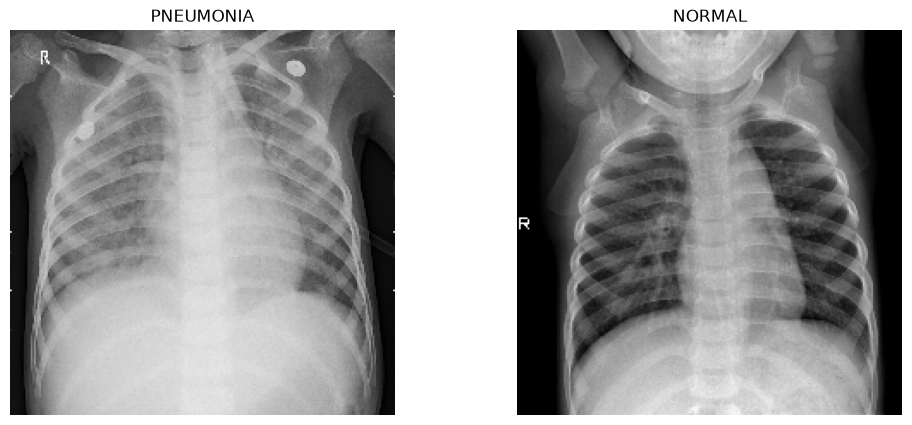

In [27]:
plt.figure(figsize=(12,5))

for i, category in enumerate(train_set_classes):
    folder = os.path.join(train_path, category)
    image_name = os.listdir(folder)[1]

    image = tf.keras.utils.load_img(
        os.path.join(folder, image_name),
        target_size=(224, 224)
    )
    plt.subplot(1,2, i+1)
    plt.imshow(image, cmap="gray")
    plt.title(category)
    plt.axis("off")
plt.show()

In [28]:
# Підготовка даних та аугментація
# Аугментація - це штучне спотворення зображень, це необхідно для того щоб модель не перенавчалася

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function = tf.keras.applications.mobilenet_v2.preprocess_input,
    validation_split=0.2,
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    seed=42
)

val_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=42
)

test_datagen = ImageDataGenerator(
    preprocessing_function = tf.keras.applications.mobilenet_v2.preprocess_input
)

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

print(f"Class mapping: {train_generator.class_indices}")

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}


In [29]:
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

In [30]:
model = models.Sequential([
    layers.Input(shape=(224,224,3)),
    base_model,
    # перетворення тензора ознак на вектор(зменшення розмірності)
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])
model

<Sequential name=sequential_1, built=True>

In [31]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [32]:
# налаштування колбеків, які будуть зупиняти навчання, змінювати швидкість навчання, зберігати проміжні результати
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_pneumonia_model.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    )
]

In [33]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.8519 - auc: 0.9097 - loss: 0.3281 - precision: 0.8693 - recall: 0.9423 - val_accuracy: 0.9415 - val_auc: 0.9820 - val_loss: 0.1759 - val_precision: 0.9612 - val_recall: 0.9600 - learning_rate: 1.0000e-04
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - accuracy: 0.9272 - auc: 0.9736 - loss: 0.1866 - precision: 0.9455 - recall: 0.9571 - val_accuracy: 0.9463 - val_auc: 0.9883 - val_loss: 0.1387 - val_precision: 0.9712 - val_recall: 0.9561 - learning_rate: 1.0000e-04
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - accuracy: 0.9315 - auc: 0.9790 - loss: 0.1630 - precision: 0.9539 - recall: 0.9539 - val_accuracy: 0.9434 - val_auc: 0.9887 - val_loss: 0.1319 - val_precision: 0.9799 - val_recall: 0.9432 - learning_rate: 1.0000e-04
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 150s 1s/step - accuracy: 0.9442 - auc: 0.9841 - loss: 0.1419 - precision: 0.9626 - recall: 0.9623 - val_accuracy: 0.9597 - val_auc: 0.9909 - val_lo

In [34]:
# Завантаження навченої моделі
MODEL_PATH = "best_pneumonia_model.keras"

model = tf.keras.models.load_model(MODEL_PATH)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,750,277 (10.49 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 328,196 (1.25 MB)

In [35]:
import numpy as np

In [36]:
# Прогнозування
# Створимо функцію яка приймає шлях до зображення
def predict_pneumonia(image_path):
    # тут змінюємо розмір зображення, тому що це необхідно для MobileNetV2
    # яка використовувалась під час навчання
    img=tf.keras.utils.load_img(
        image_path,
        target_size=(224,224)
    )
    
    # перетворюємо зображення на масив
    img_array = tf.keras.utils.img_to_array(img)
    
    # додаємо вимір batch
    # нейромережа очікує отримати зображення у форматі batch
    
    # Навіть якщо ми передаємо лише одне зображення, потрібно додати вимір batch
    # до (224, 224, 3) після (1, 224, 224, 3)
    
    img_array = np.expand_dims(img_array, axis=0)
    
    # попередня обрбка зображення
    # Під час навчання ми використовували:
    #
    # tf.keras.applications.mobilenet_v2.preprocess_input
    #
    # Ця функція перетворює значення пікселів
    # відповідно до формату, який очікує MobileNetV2.
    #
    # Звичайні значення пікселів:
    #
    # 0 ... 255
    #
    # Після preprocess_input:
    #
    # приблизно -1 ... 1
    #
    # ВАЖЛИВО:
    # Під час прогнозування потрібно використовувати
    # таку саму попередню обробку,
    # як і під час навчання.
    #
    # Інакше нейромережа отримуватиме дані
    # в іншому числовому форматі.
    
    img_array = tf.keras.applications.mobilenet_v2.preprocess_input(
        img_array
    )
    
    # передаємо зображення нейромережі
    
    # model.predict() виконує прогноз.
    #
    # Нейромережа отримує масив зображення
    # та обчислює результат через свої навчені ваги.
    #
    # verbose=0:
    # не виводимо додаткову інформацію
    # про процес прогнозування.
    #
    # Для одного зображення результат має форму:
    #
    # [[0.85]]
    #
    # Це означає, що модель повернула
    # значення 0.85 для класу PNEUMONIA.
    #
    # [0][0]:
    # беремо перший елемент першого batch.
 
    probability = model.predict(
        img_array,
        verbose=0
    )[0][0]
    
    # виводимо ймовірність
 
    # Формат .2%:
    #
    # 0.85 -> 85.00%
    #
    # Це значення виходу sigmoid,
    # а не гарантована ймовірність наявності хвороби.
    #
    # Воно показує результат роботи моделі
    # для класу PNEUMONIA.
 
    print(
        f"Результат моделі для PNEUMONIA: "
        f"{probability:.2%}"
    )
    
    # Визначаємо клас:
    if probability >= 0.5:
 
        # Модель віднесла зображення
        # до класу PNEUMONIA.
 
        print("Прогноз моделі: PNEUMONIA")
 
    else:
 
        # Модель віднесла зображення
        # до класу NORMAL.
 
        print("Прогноз моделі: NORMAL")

# Запускаємо прогноз

image_path = os.path.expanduser("~/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/test/NORMAL/NORMAL2-IM-0012-0001.jpeg")
# Тестував у wsl тому такий шлях
predict_pneumonia(image_path)    
    
    
    

Результат моделі для PNEUMONIA: 21.15%
Прогноз моделі: NORMAL
